##### The data from finance.yahoo.com was downloaded into a csv file
Note: <br> 
* The 50 day and 200 day moving averages are calculated using .rolling(window=windowsize)
* Only Rolling 52 weeks are plotted into visuals
* Plotly module was used to generate an interactive HTML file

In [32]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sn
import matplotlib.dates as mdates
import math

# Create interactive visualizations using plotly
import plotly.graph_objects as go
from plotly.subplots import make_subplots

In [33]:
os.chdir("../Data")
# os.getcwd()
# Read the csv file into a dataframe

In [34]:
# Need to read the Date column from the file as a date format. If not specified, the date will be read as string

stockdf = pd.read_csv("Combined_Stocks_daily_close.csv")

stockdf['Date'] = pd.to_datetime(stockdf['Date'], format='%m/%d/%Y').dt.date
# Validate the Stats of the numerical columns in the dataset
# stockdf.describe(include = "all")
# stockdf.info()
stockdf

,Date,Stock Name,Close Price
0,2024-12-16,Apple,251.04
1,2024-12-16,JPMorgan Chase,239.58
2,2024-12-16,Amazon.com,232.93
3,2024-12-16,Johnson & Johnson,143.85
4,2024-12-16,Caterpillar,378.92
...,...,...,...
2845,2026-11-06,JPMorgan Chase,334.49
2846,2026-11-06,Amazon.com,259.30
2847,2026-11-06,Johnson & Johnson,276.22
2848,2026-11-06,Caterpillar,558.63


In [35]:
# Ensuring that the data is sorted and is in the correct order to calculate moving averages

stockdf = stockdf.sort_values(by=['Stock Name', 'Date']).reset_index(drop=True)
stockdf

,Date,Stock Name,Close Price
0,2024-12-16,Amazon.com,232.93
1,2024-12-17,Amazon.com,231.15
2,2024-12-18,Amazon.com,220.52
3,2024-12-19,Amazon.com,223.29
4,2024-12-20,Amazon.com,224.92
...,...,...,...
2845,2026-11-02,Micron Technology,833.59
2846,2026-11-03,Micron Technology,855.10
2847,2026-11-04,Micron Technology,795.23
2848,2026-11-05,Micron Technology,656.39


In [36]:
stockdf["50 day MA"] = stockdf.groupby("Stock Name")["Close Price"].transform(lambda x: x.rolling(window=50).mean()).round(2)
stockdf

,Date,Stock Name,Close Price,50 day MA
0,2024-12-16,Amazon.com,232.93,NaN
1,2024-12-17,Amazon.com,231.15,NaN
2,2024-12-18,Amazon.com,220.52,NaN
3,2024-12-19,Amazon.com,223.29,NaN
4,2024-12-20,Amazon.com,224.92,NaN
...,...,...,...,...
2845,2026-11-02,Micron Technology,833.59,976.05
2846,2026-11-03,Micron Technology,855.10,974.94
2847,2026-11-04,Micron Technology,795.23,972.18
2848,2026-11-05,Micron Technology,656.39,966.54


In [37]:
stockdf["200 day MA"] = stockdf.groupby("Stock Name")["Close Price"].transform(lambda x: x.rolling(window=200).mean()).round(2)
stockdf

,Date,Stock Name,Close Price,50 day MA,200 day MA
0,2024-12-16,Amazon.com,232.93,NaN,NaN
1,2024-12-17,Amazon.com,231.15,NaN,NaN
2,2024-12-18,Amazon.com,220.52,NaN,NaN
3,2024-12-19,Amazon.com,223.29,NaN,NaN
4,2024-12-20,Amazon.com,224.92,NaN,NaN
...,...,...,...,...,...
2845,2026-11-02,Micron Technology,833.59,976.05,749.31
2846,2026-11-03,Micron Technology,855.10,974.94,751.78
2847,2026-11-04,Micron Technology,795.23,972.18,753.93
2848,2026-11-05,Micron Technology,656.39,966.54,755.26


In [38]:
# # Set Date as index for x-axis

# stockdf.set_index("Date", inplace=True)
# stockdf

In [39]:
# Rolling 52-week filter
end_date = stockdf['Date'].max()
start_date = end_date - pd.Timedelta(weeks=52)

stockdf_52w = stockdf[(stockdf['Date'] >= start_date) & (stockdf['Date'] <= end_date)].copy()
# end_date
# start_date
# stockdf_52w

In [40]:
# Get unique Stocks

companies = sorted(stockdf_52w['Stock Name'].dropna().unique())

# Define grid dimensions for dashboard

n_companies = len(companies)
n_cols = 2
n_rows = math.ceil(n_companies / n_cols)
n_rows

3

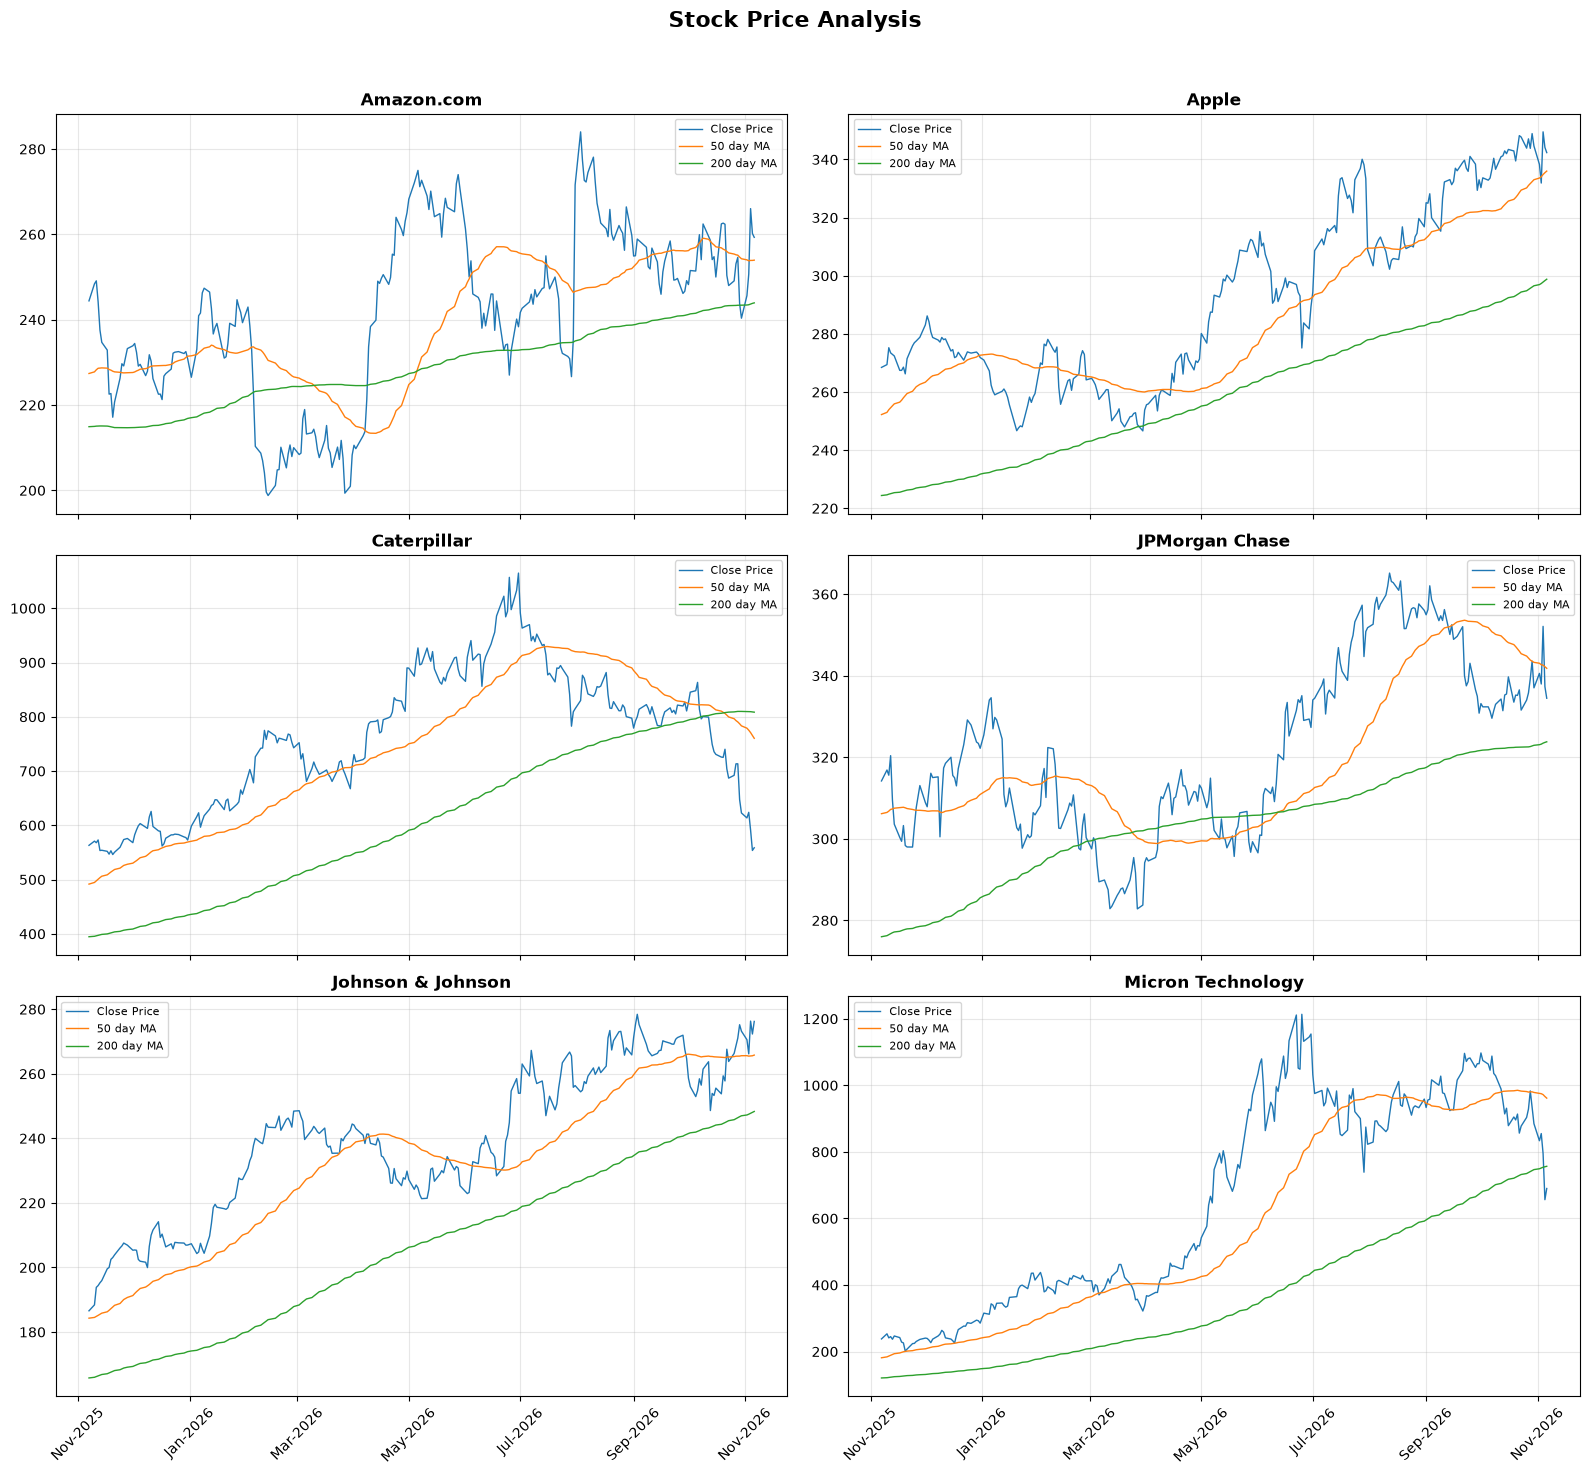

In [41]:
# Create dashboard as a grid
fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(16, 5 * n_rows),
    sharex=True
)

# Flatten axes for easy iteration
axes = axes.flatten() if n_companies > 1 else [axes]

# Plot each company
for i, company in enumerate(companies):

    ax = axes[i]

    company_df = stockdf_52w[
        stockdf_52w['Stock Name'] == company
    ]

    ax.plot(
        company_df['Date'],
        company_df['Close Price'],
        label='Close Price',
        linewidth=1.0
    )

    ax.plot(
        company_df['Date'],
        company_df['50 day MA'],
        label='50 day MA',
        linewidth=1.0
    )

    ax.plot(
        company_df['Date'],
        company_df['200 day MA'],
        label='200 day MA',
        linewidth=1.0
    )

    ax.set_title(company, fontsize=12, fontweight='bold')
#     ax.set_ylabel('Price')
    ax.grid(True, alpha=0.3)
    ax.legend(loc='best', fontsize=8)

    # Format dates
    ax.xaxis.set_major_locator(
        mdates.MonthLocator(interval=2)
    )
    ax.xaxis.set_major_formatter(
        mdates.DateFormatter('%b-%Y')
    )

    ax.tick_params(axis='x', rotation=45)

# Hide unused subplot spaces
for j in range(n_companies, len(axes)):
    axes[j].set_visible(False)

# Dashboard title
fig.suptitle(
    'Stock Price Analysis',
    fontsize=16,
    fontweight='bold'
)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

In [42]:
# Plotting using Plotly for interactive dashboard (Used ChatGPT for this section)

fig = make_subplots(
    rows=n_rows,
    cols=n_cols,
    subplot_titles=companies,
    shared_xaxes=True,
    vertical_spacing=0.10,
    horizontal_spacing=0.08
)

# Measures configuration
metric_config = {
    'Close Price': {
        'name': 'Close Price',
        'color': '#2563EB'
    },
    '50 day MA': {
        'name': '50 day MA',
        'color': '#F59E0B'
    },
    '200 day MA': {
        'name': '200 day MA',
        'color': '#16A34A'
    }
}

for i, company in enumerate(companies):

    row = (i // n_cols) + 1
    col = (i % n_cols) + 1

    company_df = stockdf_52w[stockdf_52w['Stock Name'] == company]
    
    for metric, config in metric_config.items():

        fig.add_trace(
            go.Scatter(
                x=company_df['Date'],
                y=company_df[metric],
                mode='lines',
                name=config['name'],
                legendgroup=metric,
                showlegend=(i == 0),
                line=dict(
                    color=config['color'],
                    width=1.0
                ),
                connectgaps=False
#                 hovertemplate=(
#                     '<b>' + company + '</b><br>' +
#                     'Date: %{x|%b %d, %Y}<br>' +
#                     config['name'] + ': %{y:,.2f}' +
#                     '<extra></extra>'
#                 )
            ),
            row=row,
            col=col
        )
    
    # Individual Y-axis title
    fig.update_yaxes(
#         title_text='Price',
        row=row,
        col=col
    )

    # Date formatting
    fig.update_xaxes(
        tickformat='%b-%Y',
        row=row,
        col=col
    )

    
# Dashboard Layout

fig.update_layout(
    title=dict(
        text='Stock Price Analysis',
        x=0.5,
        xanchor='center'
    ),

    height=max(450, 400 * n_rows),
    width=1400,

    hovermode='x unified',

    template='plotly_white',

    legend=dict(
#         title='Metrics',
        orientation='h',
        yanchor='bottom',
        y=1.02,
        xanchor='center',
        x=0.5,
        groupclick='togglegroup'
    ),

    margin=dict(
        l=60,
        r=40,
        t=110,
        b=60
    )
)    

# Save the dashboard as a html file
fig.write_html("Stock Price Analysis.html",include_plotlyjs=True)